# Plot Spectral Differences for Training Data #

### Sourced from Karina Zikan ###

In [19]:
import pandas as pd
import numpy as np
import os
import font
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'font'

## Create CSV File ##

In [5]:
# Format of CSV 

path_to_folder = '/Users/SILASTWICKLER/ws/HMA/snowCover/glacier-snow-cover-mapping-HMA/inputs-outputs/'
fn_trainData = 'Landsat_training_data.csv'
fp_trainData = os.path.join(path_to_folder + fn_trainData)
fn_SS = 'SpetralSignatures.csv'
fp_SS = os.path.join(path_to_folder + fn_SS)

landsat_bandCol = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']
landsat_wavelengths = [0.44, 0.48, 0.56, 0.66, 0.87, 1.61, 2.2]
class_map = {'Snow': 'S', 
             'Shadowed snow': 'SS', 
             'Ice': 'I',
             'Debris': 'DI', 
             'Rock': 'R', 
             'Water': 'W', 
             'Cloud': 'Cl'}


def build_spectral_signature_csv(
    training_csv_path,
    output_csv_path,
    band_cols,          # ordered list of band column names in the training CSV
                         # e.g. ['SR_B1','SR_B2','SR_B3','SR_B4','SR_B5','SR_B6','SR_B7']
    wavelengths,         # parallel list of wavelengths (microns), same order/length as band_cols
                         # e.g. [0.48, 0.56, 0.66, 0.85, 1.61, 2.20, 2.29]  (example - supply your own)
    class_map,           # dict: {class_label_in_csv: abbreviation_for_output}
                         # e.g. {'Snow': 'S', 'Shadowed snow': 'SS', 'Ice': 'I',
                         #       'Debris': 'DI', 'Rock': 'R', 'Water': 'W', 'Cloud': 'Cl'}
    class_col='Class',
):
    """
    Reads a per-segment/per-pixel training CSV and emits a 'wide' CSV where:
      - each ROW is a labeled statistic ('wavelength', '<abbr>_med', '<abbr>_iqr1', '<abbr>_iqr3', ...)
      - each COLUMN is a band (in the order given by band_cols/wavelengths)

    This is the RAW layout expected by scripts that do df.transpose() + df.columns = df.iloc[0]
    to pivot into "rows = bands, columns = stats" for plotting.
    """
    assert len(band_cols) == len(wavelengths), "band_cols and wavelengths must be the same length"

    df = pd.read_csv(training_csv_path)

    row_labels = ['wavelength']
    rows = [dict(zip(band_cols, wavelengths))]

    for cls, abbr in class_map.items():
        sub = df[df[class_col] == cls]
        if sub.empty:
            print(f"Warning: no rows found for class '{cls}' - stats will be NaN")

        med = sub[band_cols].median()
        q1 = sub[band_cols].quantile(0.25)
        q3 = sub[band_cols].quantile(0.75)

        row_labels += [f'{abbr}_med', f'{abbr}_iqr1', f'{abbr}_iqr3']
        rows += [med.to_dict(), q1.to_dict(), q3.to_dict()]

    out_df = pd.DataFrame(rows)
    out_df.insert(0, 'label', row_labels)
    out_df.to_csv(output_csv_path, index=False)
    print(f"Wrote {output_csv_path}  ({out_df.shape[0]} label-rows x {out_df.shape[1]-1} bands)")
    return out_df

build_spectral_signature_csv(fp_trainData, fp_SS, landsat_bandCol, landsat_wavelengths, class_map)


Wrote /Users/SILASTWICKLER/ws/HMA/snowCover/glacier-snow-cover-mapping-HMA/inputs-outputs/SpetralSignatures.csv  (22 label-rows x 7 bands)


,label,SR_B1,SR_B2,SR_B3,SR_B4,SR_B5,SR_B6,SR_B7
0,wavelength,0.440000,0.480000,0.560000,0.660000,0.870000,1.610000,2.200000
1,S_med,1.131599,1.139663,1.095441,1.069974,0.952048,0.074621,0.096986
2,S_iqr1,1.074162,1.080332,1.038915,1.017095,0.904508,0.051692,0.072678
3,S_iqr3,1.203023,1.215130,1.178399,1.162408,1.045646,0.086041,0.111708
4,SS_med,0.285685,0.223101,0.163769,0.142037,0.123425,-0.026448,0.005650
5,SS_iqr1,0.222180,0.152146,0.094716,0.069099,0.058644,-0.031739,0.001224
6,SS_iqr3,0.349834,0.285872,0.224826,0.184241,0.148879,-0.020501,0.012645
7,I_med,0.580154,0.603662,0.594403,0.589194,0.533584,0.077280,0.093233
8,I_iqr1,0.358725,0.376854,0.411096,0.416695,0.383269,0.055800,0.056932
9,I_iqr3,0.774853,0.795471,0.789154,0.789645,0.707113,0.122416,0.133460


## Load Data ##

In [16]:
# Load data
df_SS = pd.read_csv(path_to_folder + fn_SS, engine='python')
df_SS
df_SS = df_SS.transpose()
df_SS.columns = df_SS.iloc[0]
# df_SS.set_index(['wavelength'], inplace=True)
df_SS = df_SS.iloc[1:21]
#df_SS_ent = df_SS.iloc[[1,3,5,7,9,11,13,15,17,19]].astype(float)
#df_SS_spec = df_SS.iloc[[0,2,4,6,8,10,12,14,16,18]].astype(float)
df_SS_spec = df_SS.astype(float)

df_SS_spec

label,wavelength,S_med,S_iqr1,S_iqr3,SS_med,SS_iqr1,SS_iqr3,I_med,I_iqr1,I_iqr3,...,DI_iqr3,R_med,R_iqr1,R_iqr3,W_med,W_iqr1,W_iqr3,Cl_med,Cl_iqr1,Cl_iqr3
SR_B1,0.44,1.131599,1.074162,1.203023,0.285685,0.222180,0.349834,0.580154,0.358725,0.774853,...,0.151182,0.126423,0.073362,0.184892,NaN,NaN,NaN,0.899279,0.870688,0.953943
SR_B2,0.48,1.139663,1.080332,1.215130,0.223101,0.152146,0.285872,0.603662,0.376854,0.795471,...,0.182549,0.159949,0.100230,0.225488,NaN,NaN,NaN,0.917541,0.890767,0.974341
SR_B3,0.56,1.095441,1.038915,1.178399,0.163769,0.094716,0.224826,0.594403,0.411096,0.789154,...,0.271339,0.257884,0.193891,0.335744,NaN,NaN,NaN,0.893906,0.872322,0.943095
SR_B4,0.66,1.069974,1.017095,1.162408,0.142037,0.069099,0.184241,0.589194,0.416695,0.789645,...,0.301143,0.301875,0.225768,0.380922,NaN,NaN,NaN,0.895041,0.872216,0.930220
SR_B5,0.87,0.952048,0.904508,1.045646,0.123425,0.058644,0.148879,0.533584,0.383269,0.707113,...,0.321862,0.367370,0.279280,0.447523,NaN,NaN,NaN,0.846549,0.818831,0.871607
SR_B6,1.61,0.074621,0.051692,0.086041,-0.026448,-0.031739,-0.020501,0.077280,0.055800,0.122416,...,0.322505,0.425586,0.336322,0.485305,NaN,NaN,NaN,0.474308,0.395016,0.506614
SR_B7,2.20,0.096986,0.072678,0.111708,0.005650,0.001224,0.012645,0.093233,0.056932,0.133460,...,0.309413,0.369984,0.306349,0.423400,NaN,NaN,NaN,0.456509,0.394714,0.493017


## Create Graph ##

/var/folders/fp/prs872q110ggdk9cghkhr1kw0000gp/T/ipykernel_15205/494266426.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(xlabels, fontsize = 20)
/var/folders/fp/prs872q110ggdk9cghkhr1kw0000gp/T/ipykernel_15205/494266426.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(ylabels, fontsize = 20)


[Text(0.44, 1, 'SR_B1'),
 Text(0.48, 1, 'SR_B2'),
 Text(0.56, 1, 'SR_B3'),
 Text(0.66, 1, 'SR_B4'),
 Text(0.87, 1, 'SR_B5'),
 Text(1.61, 1, 'SR_B6'),
 Text(2.2, 1, 'SR_B7')]

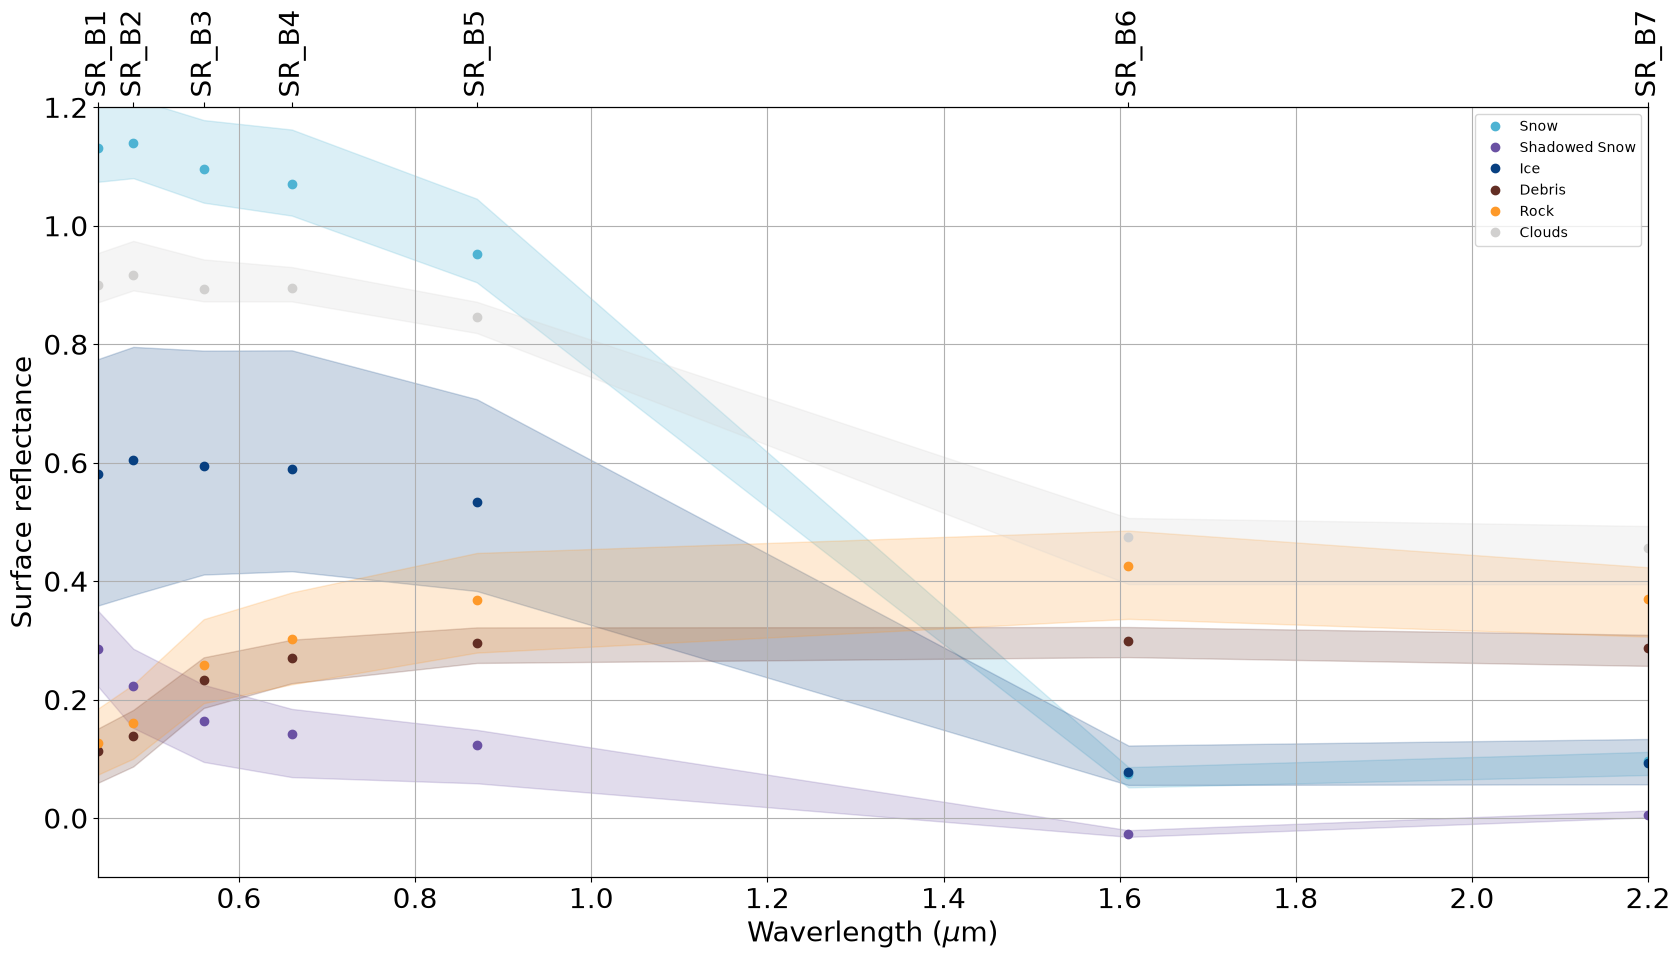

In [32]:
# Plot fig
class_colors = ['#4eb3d3', '#6a51a3', '#084081', '#632e24', '#fe9929', '#205f63', '#d1d0cf']

fig, ax = plt.subplots(figsize=(20, 10))
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['S_iqr1'], df_SS_spec['S_iqr3'], alpha=0.2, color = class_colors[0])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['S_med'], 'o', color = class_colors[0], label = 'Snow')
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['SS_iqr1'], df_SS_spec['SS_iqr3'], alpha=0.2, color = class_colors[1])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['SS_med'], 'o', color = class_colors[1], label = 'Shadowed Snow')
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['I_iqr1'], df_SS_spec['I_iqr3'], alpha=0.2, color = class_colors[2])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['I_med'], 'o', color = class_colors[2], label = 'Ice')
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['DI_iqr1'], df_SS_spec['DI_iqr3'], alpha=0.2, color = class_colors[3])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['DI_med'], 'o', color = class_colors[3], label = 'Debris')
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['R_iqr1'], df_SS_spec['R_iqr3'], alpha=0.2, color = class_colors[4])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['R_med'], 'o', color = class_colors[4], label = 'Rock')
#ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['W_iqr1'], df_SS_spec['W_iqr3'], alpha=0.2, color = class_colors[5])
#ax.plot(df_SS_spec['wavelength'], df_SS_spec['W_med'], 'o', color = class_colors[5], label = 'Water')
ax.fill_between(df_SS_spec['wavelength'], df_SS_spec['Cl_iqr1'], df_SS_spec['Cl_iqr3'], alpha=0.2, color = class_colors[6])
ax.plot(df_SS_spec['wavelength'], df_SS_spec['Cl_med'], 'o', color = class_colors[6], label = 'Clouds')


plt.grid()
ax.set_ylim([-0.1,1.2])
ax.set_xlim([0.44,2.2])
ax.set_xlabel('Waverlength ($\mu$m)', fontsize = 20)
ax.set_ylabel('Surface reflectance', fontsize = 20)
xlabels = ax.get_xticklabels()
ylabels = ax.get_yticklabels()
ax.set_xticklabels(xlabels, fontsize = 20)
ax.set_yticklabels(ylabels, fontsize = 20)
ax.legend()
ax2 = ax.twiny()
ax2.set_xticks(landsat_wavelengths)
# ax2.set_tick_params(labeltop='on')
ax2.set_xlim([0.44,2.2])
ax2.set_xticklabels(landsat_bandCol,rotation=90, fontsize = 20)